# Experiment 5 - Độ nhạy tham số EHO

- **Mục tiêu:** Quan sát ảnh hưởng của `alpha`, `beta`, số clan và số voi separation đến độ dài tour tốt nhất của D-EHO.
- **Cách thử:** Mỗi giá trị cấu hình chạy với 5 seed `[11, 23, 37, 53, 71]`; các sweep dùng riêng dataset được ghi bên dưới.
- **Kết quả:** Bảng báo cáo số run, best (min), mean, median, worst (max) và sample standard deviation của distance. Chỉ diễn giải trong các cấu hình và seed đã thử; best observed không phải optimum đã chứng minh.
- **Ngân sách:** Tối đa 4.000 objective evaluations/run, 75 runs và 120 giây tổng thời gian; mỗi solver run có time limit hợp tác tối đa 10 giây. Nếu chạm cap, số run có thể thấp hơn.
- **Chạy lại:** Chọn interpreter `.venv`, cài dependencies từ repo root, rồi chạy notebook. Đường dẫn dữ liệu hỗ trợ chạy từ root hoặc `Experiment/`.

In [1]:
from pathlib import Path
import html
import math
import statistics
import sys
from time import perf_counter

# Works from the repository root or when Jupyter starts in Experiment/.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir() and (ROOT.parent / "data").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import EHOConfig, GAConfig
from ga_eho_tsp.algorithms.eho import solve as solve_eho
from ga_eho_tsp.algorithms.ga import solve as solve_ga
from IPython.display import display, Markdown, SVG

MODE = "QUICK"
SEEDS = [11, 23, 37, 53, 71]
TOTAL_TIME_CAP_SECONDS = 120.0
PER_RUN_TIME_CAP_SECONDS = 10.0
NOTEBOOK_START = perf_counter()
RUN_COUNT = 0
MAX_RUNS = 75  # E5: 15 configurations x 5 seeds; E6 overrides to 70.
RUN_RESULTS = []
RESULT_CACHE = {}

def show_table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "| " + " | ".join(["---"] * len(headers)) + " |\n"
    text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(text))

def run_with_caps(problem, algorithm, config, tag):
    """Run only within the declared notebook run/time caps; solver has its own cooperative cap."""
    global RUN_COUNT
    if tag in RESULT_CACHE:
        return RESULT_CACHE[tag]
    elapsed = perf_counter() - NOTEBOOK_START
    if RUN_COUNT >= MAX_RUNS or elapsed >= TOTAL_TIME_CAP_SECONDS:
        return None
    remaining = TOTAL_TIME_CAP_SECONDS - elapsed
    config = __import__("dataclasses").replace(
        config, time_limit_seconds=min(PER_RUN_TIME_CAP_SECONDS, remaining)
    )
    RUN_COUNT += 1
    result = algorithm(problem, config)
    assert result.is_valid
    assert problem.route_length(result.best_route) == result.best_distance
    RUN_RESULTS.append((tag, result))
    RESULT_CACHE[tag] = result
    return result

def mean_std(values):
    if not values:
        return None, None
    return statistics.mean(values), (statistics.stdev(values) if len(values) > 1 else 0.0)

def median(values):
    return statistics.median(values) if values else None

def min_max(values):
    return (min(values), max(values)) if values else (None, None)

def plot_bars(title, labels, means, stds, ylabel="Best tour distance"):
    available = [(label, mean, std) for label, mean, std in zip(labels, means, stds)
                 if mean is not None and std is not None]
    if not available:
        display(Markdown(f"**{title}:** chưa có run hợp lệ trong giới hạn hiện tại. Restart kernel và chạy Run All để bắt đầu batch mới."))
        return
    labels, means, stds = zip(*available)
    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(max(7, len(labels) * 1.15), 4.5))
        ax.bar(range(len(labels)), means, yerr=stds, capsize=4, color="#4c8c78")
        ax.set_xticks(range(len(labels)), labels, rotation=25, ha="right")
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=.25)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    except ImportError:
        # SVG keeps the requested chart available in a notebook kernel without matplotlib.
        width, height = max(640, 90 * len(labels)), 390
        left, top, bottom = 55, 35, 105
        plot_h, plot_w = height - top - bottom, width - left - 20
        peak = max((m + s for m, s in zip(means, stds)), default=1) or 1
        pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
                  '<rect width="100%" height="100%" fill="white"/>',
                  f'<text x="{width/2}" y="22" text-anchor="middle" font-size="16">{html.escape(title)}</text>',
                  f'<line x1="{left}" y1="{top}" x2="{left}" y2="{height-bottom}" stroke="#333"/>',
                  f'<line x1="{left}" y1="{height-bottom}" x2="{width-15}" y2="{height-bottom}" stroke="#333"/>']
        slot = plot_w / max(1, len(labels)); bar_w = slot * .56
        for i, (label, mean, std) in enumerate(zip(labels, means, stds)):
            x = left + slot*i + (slot-bar_w)/2
            bar_h = mean / peak * plot_h
            y = height-bottom-bar_h
            mid = x + bar_w/2
            err = std / peak * plot_h
            pieces.extend([f'<rect x="{x:.1f}" y="{y:.1f}" width="{bar_w:.1f}" height="{bar_h:.1f}" fill="#4c8c78"/>',
                           f'<line x1="{mid:.1f}" y1="{y-err:.1f}" x2="{mid:.1f}" y2="{y+err:.1f}" stroke="#222" stroke-width="2"/>',
                           f'<line x1="{mid-6:.1f}" y1="{y-err:.1f}" x2="{mid+6:.1f}" y2="{y-err:.1f}" stroke="#222"/>',
                           f'<line x1="{mid-6:.1f}" y1="{y+err:.1f}" x2="{mid+6:.1f}" y2="{y+err:.1f}" stroke="#222"/>',
                           f'<text x="{mid:.1f}" y="{height-bottom+20}" text-anchor="middle" font-size="12">{html.escape(str(label))}</text>'])
        pieces.append('</svg>')
        display(SVG("".join(pieces)))

## Thiết lập và dữ liệu

E5.1–E5.2 dùng `15Cities-1194.txt`; E5.3–E5.4 dùng `26Cities-937.txt`. Mỗi sweep khởi tạo lại baseline EHO với budget 4.000, tối đa 250 iterations và năm seed cố định. Cell sweep có thể chạy riêng sau cell import/helpers.

In [2]:
DATA_15 = load_matrix(ROOT / "data" / "15Cities-1194.txt")
DATA_26 = load_matrix(ROOT / "data" / "26Cities-937.txt")
EVALUATION_BUDGET = 4000
BASE = EHOConfig(max_evaluations=EVALUATION_BUDGET, max_iterations=250, iterations=250)
print(f"Root: {ROOT}; seed mode: {MODE}; seeds={SEEDS}; budget={EVALUATION_BUDGET}; run cap={MAX_RUNS}")

Root: D:\ga-eho-tsp; seed mode: QUICK; seeds=[11, 23, 37, 53, 71]; budget=4000; run cap=75


## E5.1 — Ảnh hưởng của `alpha`

- **Thay đổi:** `alpha ∈ {0.1, 0.3, 0.5, 0.7, 0.9}`.
- **Giữ cố định:** Dataset 15 thành phố, `beta` và các tham số còn lại theo `EHOConfig` mặc định; 5 seed, tối đa 4.000 evaluations/run.
- **Đọc kết quả:** So best, mean, median, worst, độ lệch chuẩn và số runs hoàn tất cho từng giá trị.

| α | runs | best | mean | median | worst | std |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1 | 5 | 1804.0 | 1929.4 | 1976.0 | 2028.0 | 100.174 |
| 0.3 | 5 | 1448.0 | 1587.8 | 1570.0 | 1716.0 | 102.763 |
| 0.5 | 5 | 1430.0 | 1552.2 | 1560.0 | 1660.0 | 85.172 |
| 0.7 | 5 | 1539.0 | 1668.8 | 1672.0 | 1796.0 | 90.965 |
| 0.9 | 5 | 1678.0 | 1838.0 | 1808.0 | 2014.0 | 131.75 |

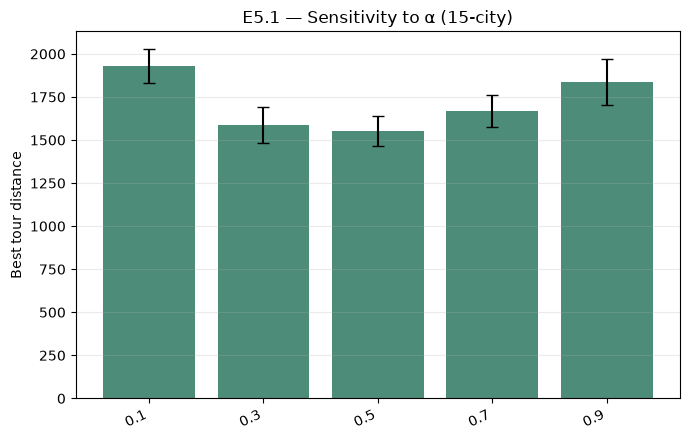

In [3]:
DATA_15 = load_matrix(ROOT / "data" / "15Cities-1194.txt")
BASE = EHOConfig(max_evaluations=4000, max_iterations=250, iterations=250)
alpha_values = [0.1, 0.3, 0.5, 0.7, 0.9]
alpha_runs = {}
for alpha in alpha_values:
    alpha_runs[alpha] = []
    for seed in SEEDS:
        result = run_with_caps(DATA_15, solve_eho,
            __import__("dataclasses").replace(BASE, alpha=alpha, seed=seed), ("alpha", alpha, seed))
        if result is None: break
        alpha_runs[alpha].append(result)
alpha_summary = []
for a, rs in alpha_runs.items():
    values = [r.best_distance for r in rs]
    mean, std = mean_std(values)
    best, worst = min_max(values)
    alpha_summary.append((a, len(rs), round(best, 3) if best is not None else "—",
                          round(mean, 3) if mean is not None else "—",
                          round(median(values), 3) if values else "—",
                          round(worst, 3) if worst is not None else "—",
                          round(std, 3) if std is not None else "—"))
show_table(["α", "runs", "best", "mean", "median", "worst", "std"], alpha_summary)
plot_bars("E5.1 — Sensitivity to α (15-city)", [str(x) for x in alpha_values],
          [mean_std([r.best_distance for r in alpha_runs[x]])[0] if alpha_runs[x] else None for x in alpha_values],
          [mean_std([r.best_distance for r in alpha_runs[x]])[1] if alpha_runs[x] else None for x in alpha_values])

## E5.2 — Ảnh hưởng của `beta`

- **Thay đổi:** `beta ∈ {0.1, 0.3, 0.5, 0.7}`.
- **Giữ cố định:** Dataset 15 thành phố, `alpha` và các tham số còn lại theo `EHOConfig` mặc định; 5 seed, tối đa 4.000 evaluations/run.
- **Đọc kết quả:** So best, mean, median, worst, độ lệch chuẩn và số runs hoàn tất cho từng giá trị.

| β | runs | best | mean | median | worst | std |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1 | 5 | 1517.0 | 1736.4 | 1735.0 | 1911.0 | 159.981 |
| 0.3 | 5 | 1539.0 | 1668.8 | 1672.0 | 1796.0 | 90.965 |
| 0.5 | 5 | 1500.0 | 1702.6 | 1752.0 | 1802.0 | 118.236 |
| 0.7 | 5 | 1636.0 | 1714.6 | 1698.0 | 1846.0 | 83.149 |

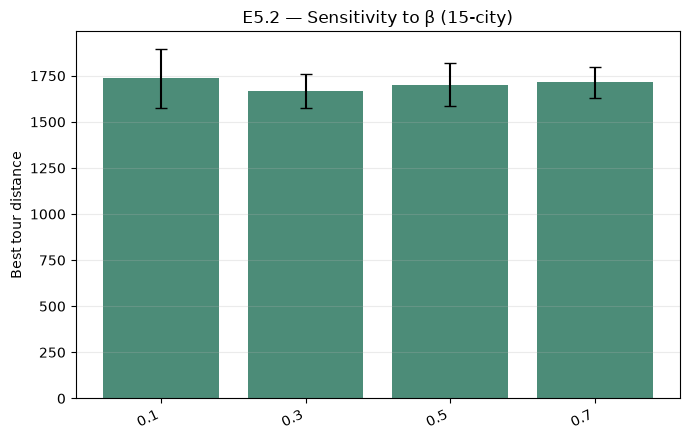

In [4]:
DATA_15 = load_matrix(ROOT / "data" / "15Cities-1194.txt")
BASE = EHOConfig(max_evaluations=4000, max_iterations=250, iterations=250)
beta_values = [0.1, 0.3, 0.5, 0.7]
beta_runs = {}
for beta in beta_values:
    beta_runs[beta] = []
    for seed in SEEDS:
        result = run_with_caps(DATA_15, solve_eho,
            __import__("dataclasses").replace(BASE, beta=beta, seed=seed), ("beta", beta, seed))
        if result is None: break
        beta_runs[beta].append(result)
show_table(["β", "runs", "best", "mean", "median", "worst", "std"], [
    (b, len(rs), min_max([r.best_distance for r in rs])[0] if rs else "—",
     round(mean_std([r.best_distance for r in rs])[0], 3) if rs else "—",
     round(median([r.best_distance for r in rs]), 3) if rs else "—",
     min_max([r.best_distance for r in rs])[1] if rs else "—",
     round(mean_std([r.best_distance for r in rs])[1], 3) if rs else "—")
    for b, rs in beta_runs.items()])
plot_bars("E5.2 — Sensitivity to β (15-city)", [str(x) for x in beta_values],
          [mean_std([r.best_distance for r in beta_runs[x]])[0] if beta_runs[x] else None for x in beta_values],
          [mean_std([r.best_distance for r in beta_runs[x]])[1] if beta_runs[x] else None for x in beta_values])

## E5.3 — Số clan khi giữ quần thể bằng nhau

- **Thay đổi:** 2, 4 hoặc 8 clan.
- **Giữ cố định:** Dataset 26 thành phố và tổng cộng 80 voi: tương ứng 40, 20 hoặc 10 voi mỗi clan; 5 seed, tối đa 4.000 evaluations/run.
- **Đọc kết quả:** So best, mean, median, worst và độ lệch chuẩn trong cùng budget; số voi mỗi clan thay đổi cùng số clan.

| clans | elephants/clan | population | runs | best | mean | median | worst | std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 40 | 80 | 5 | 1367.0 | 1570.4 | 1573.0 | 1746.0 | 138.206 |
| 4 | 20 | 80 | 5 | 1509.0 | 1672.8 | 1693.0 | 1825.0 | 114.347 |
| 8 | 10 | 80 | 5 | 1655.0 | 1810.8 | 1836.0 | 1921.0 | 100.378 |

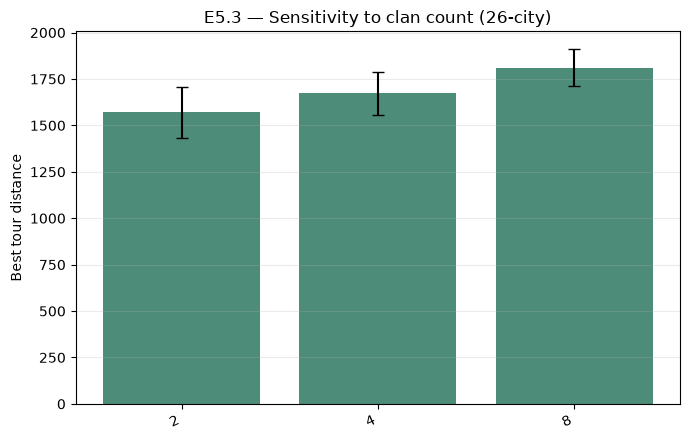

In [5]:
DATA_26 = load_matrix(ROOT / "data" / "26Cities-937.txt")
BASE = EHOConfig(max_evaluations=4000, max_iterations=250, iterations=250)
clan_values = [2, 4, 8]
clan_runs = {}
for clans in clan_values:
    elephants = 80 // clans
    assert clans * elephants == 80
    clan_runs[clans] = []
    for seed in SEEDS:
        result = run_with_caps(DATA_26, solve_eho,
            __import__("dataclasses").replace(BASE, clan_count=clans, elephants_per_clan=elephants, seed=seed),
            ("clan_count", clans, seed))
        if result is None: break
        clan_runs[clans].append(result)
show_table(["clans", "elephants/clan", "population", "runs", "best", "mean", "median", "worst", "std"],
    [(c, 80//c, 80, len(rs), min_max([r.best_distance for r in rs])[0] if rs else "—",
      round(mean_std([r.best_distance for r in rs])[0], 3) if rs else "—",
      round(median([r.best_distance for r in rs]), 3) if rs else "—",
      min_max([r.best_distance for r in rs])[1] if rs else "—",
      round(mean_std([r.best_distance for r in rs])[1], 3) if rs else "—") for c, rs in clan_runs.items()])
plot_bars("E5.3 — Sensitivity to clan count (26-city)", [str(x) for x in clan_values],
          [mean_std([r.best_distance for r in clan_runs[x]])[0] if clan_runs[x] else None for x in clan_values],
          [mean_std([r.best_distance for r in clan_runs[x]])[1] if clan_runs[x] else None for x in clan_values])

## E5.4 — Số voi được tách khỏi mỗi clan

- **Thay đổi:** `separation_count_per_clan ∈ {0, 1, 2}`.
- **Giữ cố định:** Dataset 26 thành phố, cấu hình clan baseline, 5 seed và tối đa 4.000 evaluations/run.
- **Đọc kết quả:** So best, mean, median, worst, độ lệch chuẩn và số runs hoàn tất; separation count bằng 0 tắt bước tách đàn.

| separation/clan | runs | best | mean | median | worst | std |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 5 | 1574.0 | 1692.6 | 1679.0 | 1781.0 | 88.161 |
| 1 | 5 | 1509.0 | 1672.8 | 1693.0 | 1825.0 | 114.347 |
| 2 | 5 | 1617.0 | 1725.8 | 1724.0 | 1904.0 | 113.467 |

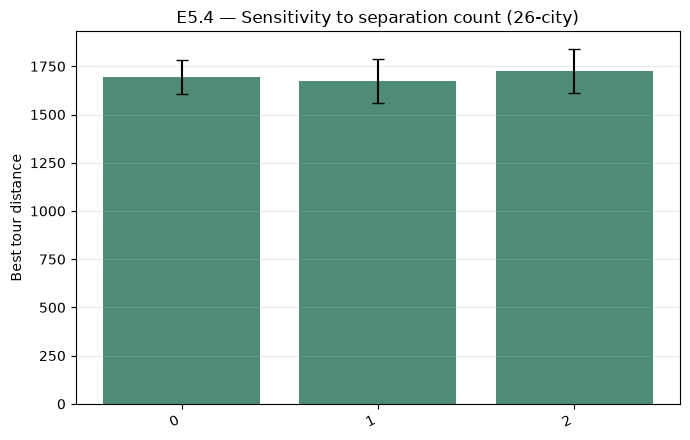

Runs completed: 75/75; elapsed notebook time: 25.68s


In [6]:
DATA_26 = load_matrix(ROOT / "data" / "26Cities-937.txt")
BASE = EHOConfig(max_evaluations=4000, max_iterations=250, iterations=250)
separation_values = [0, 1, 2]
separation_runs = {}
for count in separation_values:
    separation_runs[count] = []
    for seed in SEEDS:
        result = run_with_caps(DATA_26, solve_eho,
            __import__("dataclasses").replace(BASE, separation_count_per_clan=count, seed=seed),
            ("separation_count", count, seed))
        if result is None: break
        separation_runs[count].append(result)
show_table(["separation/clan", "runs", "best", "mean", "median", "worst", "std"],
    [(c, len(rs), min_max([r.best_distance for r in rs])[0] if rs else "—",
      round(mean_std([r.best_distance for r in rs])[0], 3) if rs else "—",
      round(median([r.best_distance for r in rs]), 3) if rs else "—",
      min_max([r.best_distance for r in rs])[1] if rs else "—",
      round(mean_std([r.best_distance for r in rs])[1], 3) if rs else "—") for c, rs in separation_runs.items()])
plot_bars("E5.4 — Sensitivity to separation count (26-city)", [str(x) for x in separation_values],
          [mean_std([r.best_distance for r in separation_runs[x]])[0] if separation_runs[x] else None for x in separation_values],
          [mean_std([r.best_distance for r in separation_runs[x]])[1] if separation_runs[x] else None for x in separation_values])
print(f"Runs completed: {RUN_COUNT}/{MAX_RUNS}; elapsed notebook time: {perf_counter()-NOTEBOOK_START:.2f}s")